In [1]:
import torch
from torch_geometric.data import Data
from collections import Counter
import matplotlib.pyplot as plt
import random

. @Oxford/Hilary/Geometric deep learning/Mini-project-code/torch-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import json


def load_cayley_dicts_jsonl(path):
    cayley_dicts = []
    with open(path, "r") as f:
        for line in f:
            cayley_dicts.append(json.loads(line))
    return cayley_dicts

cayley_dict_unique_100 = load_cayley_dicts_jsonl("../data/cayley_dict_unique_100.jsonl")
cayley_dict_five_gens_each_50 = load_cayley_dicts_jsonl("../data/cayley_five_gens_each_50.jsonl")
cayley_dict_ten_gens_each_50 = load_cayley_dicts_jsonl("../data/cayley_ten_gens_each_50.jsonl")
cayley_dict_unique_51_200 = load_cayley_dicts_jsonl("../data/cayley_dict_unique_51_200.jsonl")
cayley_dict_five_gens_each_51_150 = load_cayley_dicts_jsonl("../data/cayley_dict_five_gens_each_51_150.jsonl")
#cayley_dict_unique_99 = load_cayley_dicts_jsonl("../data/cayley_unique_1024.jsonl")
#cayley_dict_five_gens_each_49 = load_cayley_dicts_jsonl("../data/cayley_five_gens_each.jsonl")
#cayley_dict_unique_151_250 = load_cayley_dicts_jsonl("../data/cayley_dict_unique_151_250.jsonl")
#cayley_dict_five_gens_each_51_150 = load_cayley_dicts_jsonl("../data/cayley_five_gens_each_51_150.jsonl")


In [3]:
cayley_dict_unique_200 = cayley_dict_unique_100 + cayley_dict_unique_51_200[791::]

In [80]:
from numpy import dtype


print(torch.tensor(cayley_dict_unique_200[10]['edge_index'], dtype=torch.long).t().contiguous())
print(cayley_dict_unique_200[10]['edge_index'])
print(cayley_dict_unique_200[10]['edge_label'])
list = []
for i,l in enumerate(cayley_dict_unique_200[10]['edge_index']):
    list.append(l + [cayley_dict_unique_200[10]['edge_label'][i]])
list


tensor([[0, 0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7],
        [1, 2, 3, 4, 4, 0, 5, 6, 6, 1, 0, 7, 7, 3, 2, 5]])
[[0, 1], [0, 2], [1, 3], [1, 4], [2, 4], [2, 0], [3, 5], [3, 6], [4, 6], [4, 1], [5, 0], [5, 7], [6, 7], [6, 3], [7, 2], [7, 5]]
[1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2]


[[0, 1, 1],
 [0, 2, 2],
 [1, 3, 1],
 [1, 4, 2],
 [2, 4, 1],
 [2, 0, 2],
 [3, 5, 1],
 [3, 6, 2],
 [4, 6, 1],
 [4, 1, 2],
 [5, 0, 1],
 [5, 7, 2],
 [6, 7, 1],
 [6, 3, 2],
 [7, 2, 1],
 [7, 5, 2]]

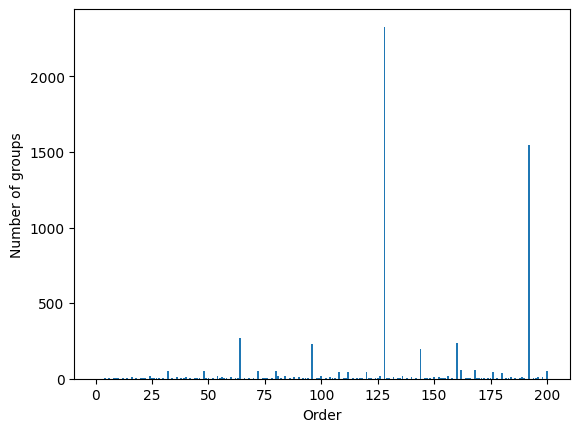

In [79]:
num_vertices_list = [d["num_vertices"] for d in cayley_dict_unique_200]

counts = Counter(num_vertices_list)
xs = sorted(counts.keys())
ys = [counts[x] for x in xs]
plt.figure()
plt.bar(xs, ys)
plt.xlabel("Order")
plt.ylabel("Number of groups")
plt.show()

Now we can start with the abelian classification. We will go from CayleyDict ->PyG dataset -> GNN -> train

In [30]:
def build_pyg_dataset(cayley_dicts):
    max_num_generators = max(d["num_generators"] for d in cayley_dicts)
    dataset = []
    for d in cayley_dicts:
        #we transpose the edge_index because GINE expects edge index to have dimension 2 \times num_edges
        edge_index = torch.tensor(d["edge_index"], dtype=torch.long).t().contiguous()
        edge_attr = torch.zeros((d["num_edges"], max_num_generators))
        num_generators = d["num_generators"]
        gen_labels = d["edge_label"][0:num_generators]
        for i, g in enumerate(d["edge_label"]):
            edge_attr[i, gen_labels.index(g)] = 1.0
        #So edge_attr is a matrix where each row corresponds to an edge with only one 1 at column i where edge_attr has generator i. 
        x = torch.ones((d["num_vertices"], 1)) #each row corresponds to a vertex and we initially start with scalar features
        y = torch.tensor([d["is_abelian"]], dtype=torch.long)
        dataset.append(Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y))

    return dataset, max_num_generators
    

In [ ]:
def split_dataset(dataset, seed=0):
    random.seed(seed)
    random.shuffle(dataset)
    n = len(dataset)
    train = dataset[:int(0.7*n)]
    val   = dataset[int(0.7*n):int(0.85*n)]
    test  = dataset[int(0.85*n):]

    return train, val, test




In [85]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_mean_pool

class GNN(nn.Module):
    def __init__(self, edge_dim):
        super().__init__()

        def mlp(in_dim, out_dim):
            return nn.Sequential(
                nn.Linear(in_dim, out_dim),
                nn.ReLU(),
                nn.Linear(out_dim, out_dim)
            )
        #here mlp(x,y) means that the node that there are x features per node in input and y features per node in ouput. 
        self.conv1 = GINEConv(mlp(1, 64), edge_dim=edge_dim)
        self.conv2 = GINEConv(mlp(64, 64), edge_dim=edge_dim)
        self.conv3 = GINEConv(mlp(64, 64), edge_dim=edge_dim)
        #edge_dim projects the edges to the dimension of the nodes. 
        self.lin = nn.Linear(64, 2) #outputs prediction over 2 classes yes or no.
        #So here each node will have 2 features of whether it elongs
    def forward(self, x, edge_index, edge_attr, batch):
        x = F.relu(self.conv1(x, edge_index, edge_attr))
        x = F.relu(self.conv2(x, edge_index, edge_attr))
        x = F.relu(self.conv3(x, edge_index, edge_attr))

        x = global_mean_pool(x, batch)
        return self.lin(x)

In [87]:
from torch_geometric.loader import DataLoader

def train_model(dataset, edge_dim):
    train_set, val_set, test_set = split_dataset(dataset, seed = 10)

    train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
    val_loader   = DataLoader(val_set, batch_size=16)
    test_loader  = DataLoader(test_set, batch_size=16)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = GNN(edge_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(10):
        model.train()
        total_loss = 0

        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
            loss = F.cross_entropy(out, batch.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        correct = 0
        total = 0
        for batch in val_loader:
            batch = batch.to(device)
            out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
            pred = out.argmax(dim=1)
            correct += (pred == batch.y).sum().item()
            total += batch.y.size(0)

        print(f"Epoch {epoch}, Loss {total_loss:.3f}, Val Acc {correct/total:.3f}")

    return model, test_loader

In [88]:
def test_model(model, test_loader):
    device = next(model.parameters()).device
    model.eval()
    correct = 0
    total = 0

    for batch in test_loader:
        batch = batch.to(device)
        out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        pred = out.argmax(dim=1)

        correct += (pred == batch.y).sum().item()
        total += batch.y.size(0)

    print("Test accuracy:", correct / total)

In [89]:
dataset, edge_dim = build_pyg_dataset(cayley_dict_unique_200)
model, test_loader = train_model(dataset, edge_dim)
test_model(model, test_loader)

Epoch 0, Loss 55.231, Val Acc 0.933
Epoch 1, Loss 44.062, Val Acc 0.969
Epoch 2, Loss 37.716, Val Acc 0.969
Epoch 3, Loss 37.755, Val Acc 0.969
Epoch 4, Loss 36.808, Val Acc 0.969
Epoch 5, Loss 36.750, Val Acc 0.969
Epoch 6, Loss 36.893, Val Acc 0.969
Epoch 7, Loss 36.377, Val Acc 0.969
Epoch 8, Loss 36.855, Val Acc 0.969
Epoch 9, Loss 36.530, Val Acc 0.969
Test accuracy: 0.9802197802197802


Why do we get this result? Maybe it is just picking up to the majority class here.

In [53]:
dataset, edge_dim = build_pyg_dataset(cayley_dict_unique_200)
def label_stats(dataset):
    ys = [int(d.y.item()) for d in dataset]
    c = Counter(ys)
    print("counts:", c)
    print("fraction abelian:", c[1] / len(ys))
    print("majority baseline acc:", max(c[0], c[1]) / len(ys))

label_stats(dataset)

counts: Counter({0: 5676, 1: 389})
fraction abelian: 0.06413849958779884
majority baseline acc: 0.9358615004122012


## Comprehensive Model Evaluation

Train on the unique Cayley graphs dataset and evaluate with full metrics.

In [104]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
from sklearn.model_selection import train_test_split

def split_dataset_equal(dataset, seed=0):
    dataset = list(dataset)  # avoid mutating original
    labels = np.array([int(d.y) for d in dataset])
    idx = np.arange(len(dataset))

    train_idx, temp_idx = train_test_split(
        idx,
        test_size=0.30,
        random_state=seed,
        stratify=labels
    )

    temp_labels = labels[temp_idx]
    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=0.50,
        random_state=seed,
        stratify=temp_labels
    )

    train = [dataset[i] for i in train_idx]
    val   = [dataset[i] for i in val_idx]
    test  = [dataset[i] for i in test_idx]

    return train, val, test

In [105]:
def evaluate_model(model, loader, cayley_dicts_test=None):
    """
    Returns all predictions and ground-truth labels for a DataLoader.
    Optionally also returns group metadata (order, group_id) for breakdown analysis.
    """
    device = next(model.parameters()).device
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
            preds = out.argmax(dim=1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(batch.y.cpu().tolist())

    return np.array(all_preds), np.array(all_labels)



In [106]:



def full_evaluation(dataset, edge_dim, cayley_dicts=None, epochs=30, seed=10):
    """Train and run comprehensive evaluation on the test split."""
    from torch_geometric.loader import DataLoader

    train_set, val_set, test_set = split_dataset_equal(dataset, seed=seed)

    train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=16)
    test_loader  = DataLoader(test_set,  batch_size=16)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GNN(edge_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    print(f"Training on {len(train_set)} | Val {len(val_set)} | Test {len(test_set)}")
    print(f"Majority baseline (train): {max(Counter(int(d.y) for d in train_set).values()) / len(train_set):.3f}")

    train_losses, val_accs = [], []
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
            loss = F.cross_entropy(out, batch.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        val_preds, val_labels = evaluate_model(model, val_loader)
        val_acc = (val_preds == val_labels).mean()
        train_losses.append(total_loss)
        val_accs.append(val_acc)
        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1:3d} | Loss {total_loss:.3f} | Val Acc {val_acc:.3f}")

    # --- Test metrics ---
    test_preds, test_labels = evaluate_model(model, test_loader)
    print("\n=== Test Set Results ===")
    print(classification_report(test_labels, test_preds, target_names=["Non-abelian", "Abelian"]))

    cm = confusion_matrix(test_labels, test_preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Non-abelian", "Abelian"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    disp.plot(ax=axes[0], colorbar=False)
    axes[0].set_title("Confusion Matrix (Test Set)")

    axes[1].plot(train_losses, label="Train Loss")
    ax2 = axes[1].twinx()
    ax2.plot(val_accs, color="orange", label="Val Acc")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    ax2.set_ylabel("Val Accuracy")
    axes[1].set_title("Training Curve")
    axes[1].legend(loc="upper left")
    ax2.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

    return model, test_loader, test_preds, test_labels


Training on 4245 | Val 910 | Test 910
Majority baseline (train): 0.936
Epoch   5 | Loss 34.190 | Val Acc 0.966
Epoch  10 | Loss 33.415 | Val Acc 0.966
Epoch  15 | Loss 32.910 | Val Acc 0.966
Epoch  20 | Loss 33.585 | Val Acc 0.966
Epoch  25 | Loss 33.108 | Val Acc 0.966
Epoch  30 | Loss 33.038 | Val Acc 0.966

=== Test Set Results ===
              precision    recall  f1-score   support

 Non-abelian       0.96      1.00      0.98       851
     Abelian       1.00      0.46      0.63        59

    accuracy                           0.96       910
   macro avg       0.98      0.73      0.80       910
weighted avg       0.97      0.96      0.96       910



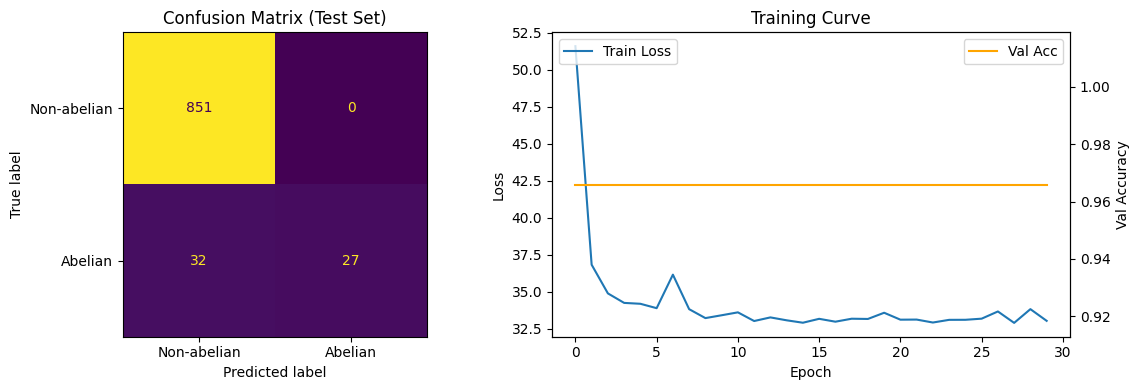

In [107]:


# Build dataset using the working build_pyg_dataset (unique 100 file)
dataset_eval, edge_dim_eval = build_pyg_dataset(cayley_dict_unique_200)
model_eval, test_loader_eval, test_preds, test_labels = full_evaluation(
    dataset_eval, edge_dim_eval, epochs=30
)

In [ ]:
def accuracy_by_group_order(model, cayley_dicts, dataset):
    """
    Break down accuracy by group order (num_vertices).
    cayley_dicts and dataset must be aligned (same order, no shuffle).
    """
    device = next(model.parameters()).device
    model.eval()

    from torch_geometric.loader import DataLoader
    loader = DataLoader(dataset, batch_size=1, shuffle=False)

    results = []  # (group_order, group_id, label, pred)
    with torch.no_grad():
        for data, d in zip(loader, cayley_dicts):
            data = data.to(device)
            out = model(data.x, data.edge_index, data.edge_attr, data.batch)
            pred = out.argmax(dim=1).item()
            results.append({
                "order": d["num_vertices"],
                "group_id": d["group_id"],
                "label": d["is_abelian"],
                "pred": pred,
                "correct": int(pred == d["is_abelian"]),
            })

    # Aggregate by order
    from collections import defaultdict
    order_stats = defaultdict(lambda: {"correct": 0, "total": 0})
    for r in results:
        order_stats[r["order"]]["correct"] += r["correct"]
        order_stats[r["order"]]["total"] += 1

    orders = sorted(order_stats.keys())
    accs = [order_stats[o]["correct"] / order_stats[o]["total"] for o in orders]
    totals = [order_stats[o]["total"] for o in orders]

    fig, ax = plt.subplots(figsize=(12, 4))
    bars = ax.bar(orders, accs, color=["green" if a == 1.0 else "steelblue" if a > 0.7 else "tomato" for a in accs])
    ax.axhline(y=max(Counter(r["label"] for r in results).values()) / len(results),
               color="red", linestyle="--", label="Majority baseline")
    ax.set_xlabel("Group order (num vertices)")
    ax.set_ylabel("Accuracy")
    ax.set_title("Per-Order Test Accuracy")
    ax.set_ylim(0, 1.05)
    ax.legend()
    # Annotate with counts
    for bar, total in zip(bars, totals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
                str(total), ha="center", va="bottom", fontsize=7)
    plt.tight_layout()
    plt.show()

    # Print failures
    failures = [r for r in results if not r["correct"]]
    print(f"\nMisclassified: {len(failures)}/{len(results)}")
    if failures:
        print(f"{'Group':12s} {'Order':>6s} {'Label':>8s} {'Pred':>6s}")
        for r in failures[:20]:  # show up to 20
            label_str = "abelian" if r["label"] == 1 else "non-ab."
            pred_str  = "abelian" if r["pred"]  == 1 else "non-ab."
            print(f"{r['group_id']:12s} {r['order']:>6d} {label_str:>8s} {pred_str:>8s}")

# Run on the full dataset (no train/test split) to see per-order coverage
accuracy_by_group_order(model_eval, cayley_dict_unique_100, dataset_eval)